TITLE :  DEMAND FORECASTING

Dataset Shape: (6435, 8)
   Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1  05-02-2010    1643690.90             0        42.31       2.572   
1      1  12-02-2010    1641957.44             1        38.51       2.548   
2      1  19-02-2010    1611968.17             0        39.93       2.514   
3      1  26-02-2010    1409727.59             0        46.63       2.561   
4      1  05-03-2010    1554806.68             0        46.50       2.625   

          CPI  Unemployment  
0  211.096358         8.106  
1  211.242170         8.106  
2  211.289143         8.106  
3  211.319643         8.106  
4  211.350143         8.106  


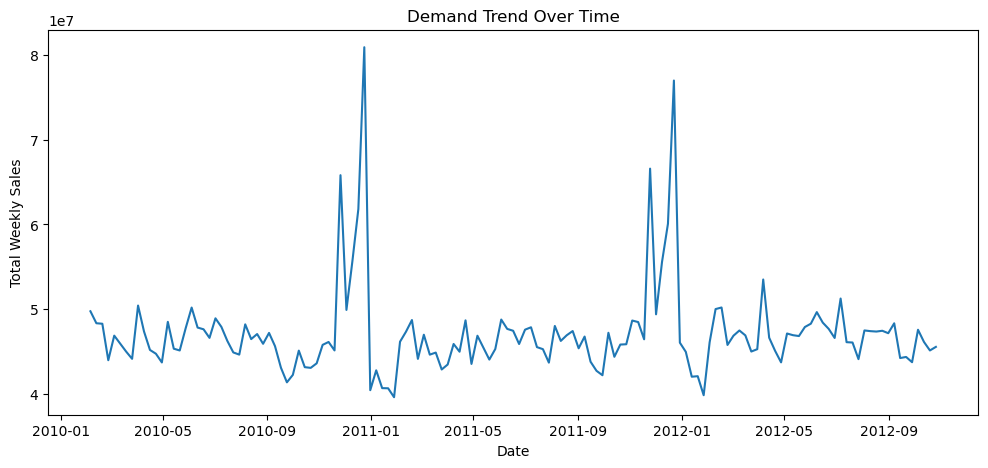


Random Forest R2 (Baseline): 0.5758464875280478

XGBoost Train R2: 0.9986986026176944
XGBoost Test R2: 0.9900306945651075
Test MAPE: 3.6811185845045697

Feature Importance
                Feature  Importance
19       rolling_mean_4    0.654861
15                lag_1    0.138922
21       rolling_mean_8    0.124352
17                lag_4    0.018994
10                 week    0.017369
16                lag_2    0.010265
9                 month    0.010129
1          Holiday_Flag    0.005907
18                lag_8    0.004533
20        rolling_std_4    0.002647
13            month_sin    0.002338
14            month_cos    0.002175
8   unemployment_change    0.001586
11                 year    0.001097
7          Unemployment    0.000744
4     fuel_price_change    0.000725
12                trend    0.000652
5                   CPI    0.000625
6            cpi_change    0.000612
2           Temperature    0.000539
3            Fuel_Price    0.000498
0                 Store    0.000431

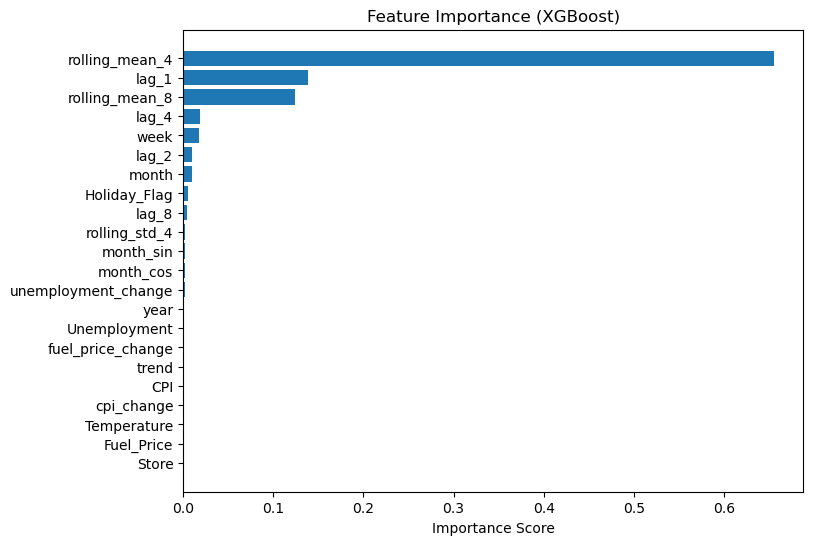

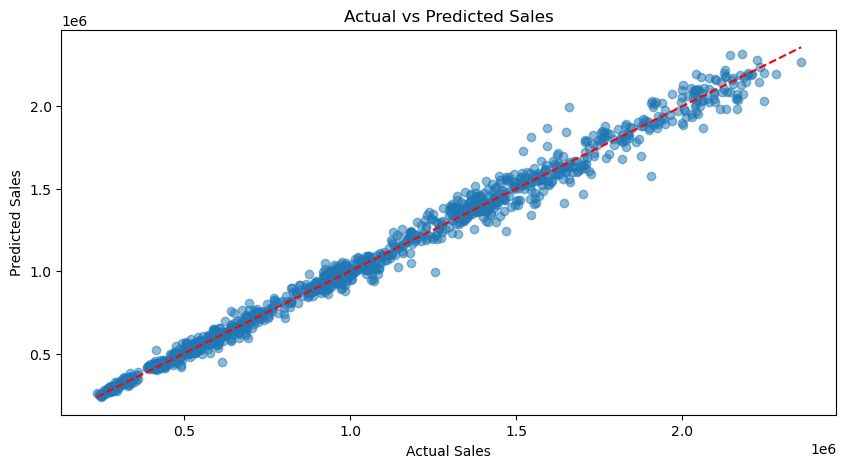

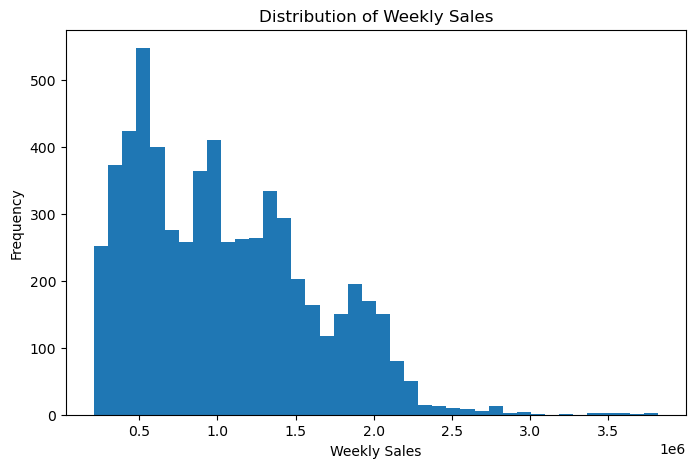

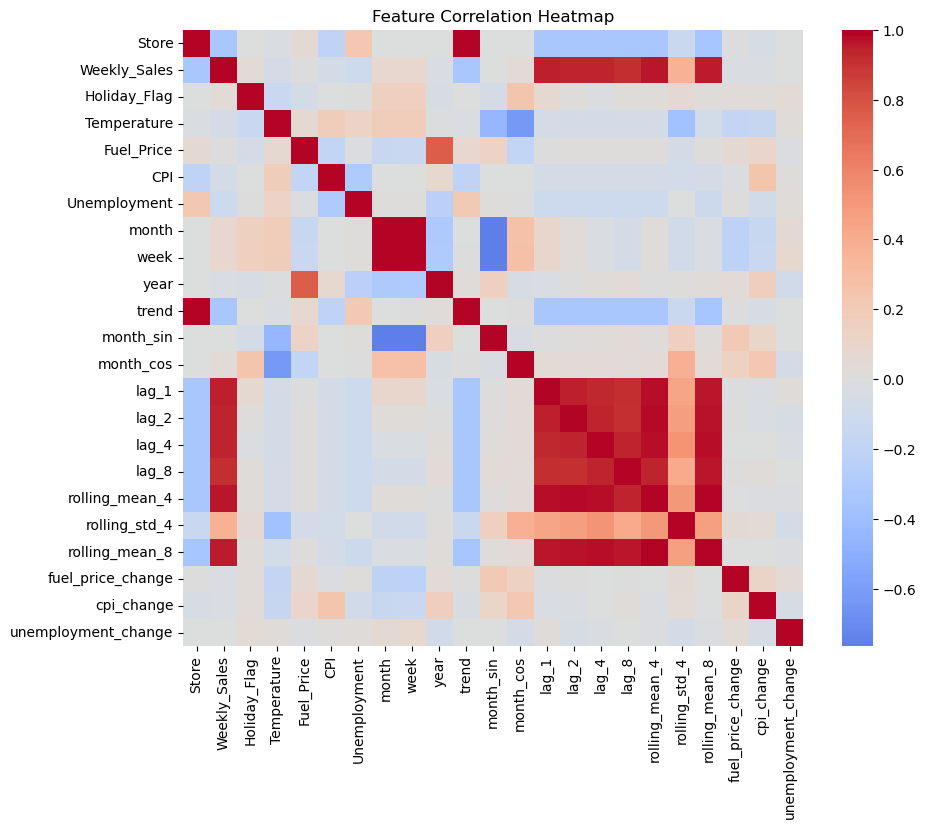

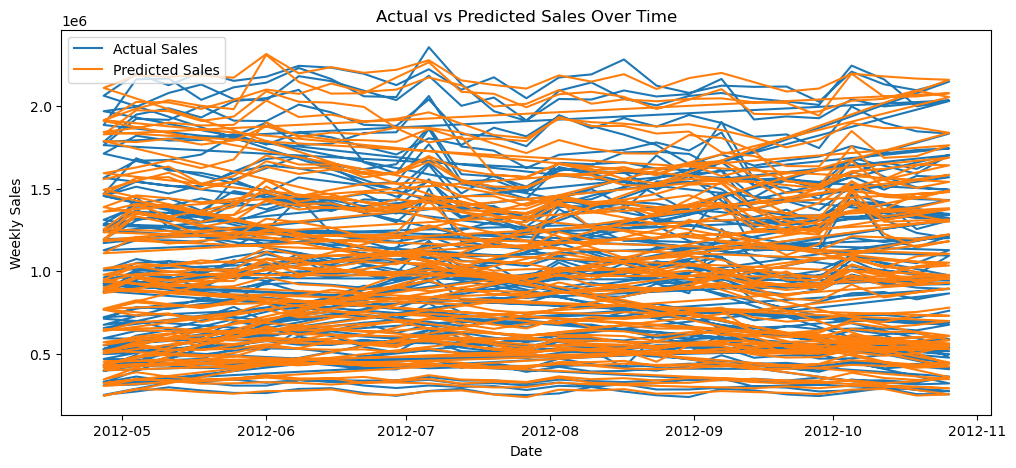


MODEL COMPARISON
Random Forest R2 : 0.5758464875280478
XGBoost Test R2 : 0.9900306945651075


In [11]:
# =====================================================
# 1. Import Libraries
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


# =====================================================
# 2. Load Dataset
# =====================================================

df = pd.read_csv("Walmart.csv")

print("Dataset Shape:", df.shape)
print(df.head())


# =====================================================
# 3. Convert Date
# =====================================================

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

df = df.sort_values(['Store','Date']).reset_index(drop=True)


# =====================================================
# 4. Demand Trend Graph
# =====================================================

plt.figure(figsize=(12,5))

trend = df.groupby('Date')['Weekly_Sales'].sum()

plt.plot(trend)

plt.title("Demand Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")

plt.show()


# =====================================================
# 5. Time Features
# =====================================================

df['month'] = df['Date'].dt.month
df['week'] = df['Date'].dt.isocalendar().week.astype(int)
df['year'] = df['Date'].dt.year

# Trend feature
df['trend'] = np.arange(len(df))


# =====================================================
# 6. Seasonality Encoding
# =====================================================

df['month_sin'] = np.sin(2*np.pi*df['month']/12)
df['month_cos'] = np.cos(2*np.pi*df['month']/12)


# =====================================================
# 7. Encode Store
# =====================================================

encoder = LabelEncoder()
df['Store'] = encoder.fit_transform(df['Store'])


# =====================================================
# 8. Lag Features
# =====================================================

df['lag_1'] = df.groupby('Store')['Weekly_Sales'].shift(1)
df['lag_2'] = df.groupby('Store')['Weekly_Sales'].shift(2)
df['lag_4'] = df.groupby('Store')['Weekly_Sales'].shift(4)
df['lag_8'] = df.groupby('Store')['Weekly_Sales'].shift(8)


# =====================================================
# 9. Rolling Statistics
# =====================================================

df['rolling_mean_4'] = df.groupby('Store')['Weekly_Sales'] \
    .transform(lambda x: x.shift(1).rolling(4).mean())

df['rolling_std_4'] = df.groupby('Store')['Weekly_Sales'] \
    .transform(lambda x: x.shift(1).rolling(4).std())

df['rolling_mean_8'] = df.groupby('Store')['Weekly_Sales'] \
    .transform(lambda x: x.shift(1).rolling(8).mean())


# =====================================================
# 10. Economic Change Features
# =====================================================

df['fuel_price_change'] = df.groupby('Store')['Fuel_Price'].diff()
df['cpi_change'] = df.groupby('Store')['CPI'].diff()
df['unemployment_change'] = df.groupby('Store')['Unemployment'].diff()


# =====================================================
# 11. Remove Missing Values
# =====================================================

df = df.dropna()


# =====================================================
# 12. Feature Selection
# =====================================================

features = [

'Store',
'Holiday_Flag',
'Temperature',

'Fuel_Price',
'fuel_price_change',

'CPI',
'cpi_change',

'Unemployment',
'unemployment_change',

'month',
'week',
'year',
'trend',

'month_sin',
'month_cos',

'lag_1',
'lag_2',
'lag_4',
'lag_8',

'rolling_mean_4',
'rolling_std_4',
'rolling_mean_8'

]

X = df[features]

y = df['Weekly_Sales']


# =====================================================
# 13. Time-Based Train-Test Split
# =====================================================

split_date = df['Date'].quantile(0.8)

train = df['Date'] < split_date
test = df['Date'] >= split_date

X_train = X[train]
X_test = X[test]

y_train = y[train]
y_test = y[test]


# =====================================================
# 14. Random Forest Baseline
# =====================================================

baseline_features = [

'Store',
'Holiday_Flag',
'Temperature',
'Fuel_Price',
'CPI',
'Unemployment',
'month',
'week',
'year'

]

X_train_rf = X_train[baseline_features]
X_test_rf = X_test[baseline_features]

rf = RandomForestRegressor(

    n_estimators=50,
    max_depth=4,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42

)

rf.fit(X_train_rf, y_train)

rf_pred = rf.predict(X_test_rf)

rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest R2 (Baseline):", rf_r2)


# =====================================================
# 15. XGBoost Model
# =====================================================

xgb = XGBRegressor(

    n_estimators=1200,
    learning_rate=0.02,
    max_depth=6,

    subsample=0.9,
    colsample_bytree=0.9,

    reg_lambda=1,
    reg_alpha=0.1,

    random_state=42

)

xgb.fit(X_train, y_train)

train_pred = xgb.predict(X_train)
test_pred = xgb.predict(X_test)

print("\nXGBoost Train R2:", r2_score(y_train, train_pred))
print("XGBoost Test R2:", r2_score(y_test, test_pred))


# =====================================================
# 16. MAPE (Percentage Error)
# =====================================================

def mape(y_true,y_pred):

    return np.mean(np.abs((y_true - y_pred)/y_true))*100

print("Test MAPE:", mape(y_test,test_pred))


# =====================================================
# 17. Feature Importance
# =====================================================

importance = xgb.feature_importances_

feature_importance = pd.DataFrame({

    'Feature':features,
    'Importance':importance

})

feature_importance = feature_importance.sort_values(by='Importance',ascending=False)

print("\nFeature Importance")

print(feature_importance)


# =====================================================
# 18. Feature Importance Graph
# =====================================================

plt.figure(figsize=(8,6))

plt.barh(feature_importance['Feature'],feature_importance['Importance'])

plt.title("Feature Importance (XGBoost)")
plt.xlabel("Importance Score")

plt.gca().invert_yaxis()

plt.show()


# =====================================================
# 19. Actual vs Predicted
# =====================================================

plt.figure(figsize=(10,5))

plt.scatter(y_test,test_pred,alpha=0.5)

plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    'r--'
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted Sales")

plt.show()


# =====================================================
# 20. Sales Distribution
# =====================================================

plt.figure(figsize=(8,5))

plt.hist(df['Weekly_Sales'],bins=40)

plt.title("Distribution of Weekly Sales")

plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")

plt.show()


# =====================================================
# 21. Correlation Heatmap
# =====================================================

plt.figure(figsize=(10,8))

corr = df.corr(numeric_only=True)

sns.heatmap(corr,cmap="coolwarm",center=0)

plt.title("Feature Correlation Heatmap")

plt.show()


# =====================================================
# 22. Prediction Over Time
# =====================================================

plt.figure(figsize=(12,5))

plt.plot(df.loc[test,'Date'],y_test,label="Actual Sales")

plt.plot(df.loc[test,'Date'],test_pred,label="Predicted Sales")

plt.legend()

plt.title("Actual vs Predicted Sales Over Time")

plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.show()




Abstract:


Accurate demand forecasting plays a crucial role in retail management as it enables better inventory planning, optimized supply chain operations, and improved business decision-making. In this project, a machine learning-based demand forecasting system is developed to predict weekly sales for Walmart stores using historical sales data along with environmental and economic indicators. The primary objective of the project is to analyze the factors influencing retail demand and to build predictive models capable of capturing temporal patterns and sales fluctuations.

The dataset used in this study contains several features including Date, Store, Weekly Sales, Holiday Flag, Temperature, Fuel Price, Consumer Price Index (CPI), and Unemployment rate. These features are part of the dataset and represent important factors that influence consumer purchasing behaviour and retail demand. From the Date attribute, additional temporal features such as month, week, and year were extracted to capture seasonal variations in sales. To model cyclical seasonal patterns effectively, sine and cosine transformations of the month variable were applied.

A major component of the methodology involves feature engineering to incorporate historical sales behavior. Lag variables such as lag₁, lag₂, lag₄, and lag₈ represent sales from previous weeks and enable the model to learn temporal dependencies in demand patterns. Rolling statistical features including rolling_mean₄, rolling_std₄, and rolling_mean₈ capture short-term sales trends and variability by computing moving averages and standard deviations over past observations. Additionally, economic variation indicators such as fuel price change, CPI change, and unemployment change were calculated using first-order differencing to capture short-term economic fluctuations that may influence purchasing power and consumer spending.

Two machine learning models were implemented and compared in this project. A Random Forest Regressor was used as a baseline model due to its 
robustness and capability to model nonlinear relationships in structured datasets. The primary forecasting model used was Extreme Gradient Boosting (XGBoost), an advanced ensemble learning technique that improves prediction accuracy through sequential boosting and regularization mechanisms. A time-based train–test split was used to preserve the chronological order of the dataset. Model performance was evaluated using R² score and Mean Absolute Percentage Error (MAPE).

Experimental results demonstrate that XGBoost provides higher predictive accuracy than Random Forest, as it more effectively captures the complex relationships between historical sales patterns, seasonal effects, and economic indicators. Feature importance analysis further reveals that lag features and rolling statistical features contribute most significantly to demand prediction, highlighting the strong influence of historical sales behavior on future retail demand.

